# 02. Data Preparation (Bab 5.1 - 5.4)

**Proyek:** Perbandingan Kinerja Naive Baseline, XGBoost, dan Long Short-Term Memory (LSTM) dalam Prediksi Jumlah Kasus Demam Berdarah Dengue (DBD) Berdasarkan Faktor Meteorologi di DKI Jakarta (2010-2024)  
**Tahap L-M-O-P:** `[L]` Data Preparation (Minggu 2 / LKM 11 Poin 4-6: sampai **Bab 5.4**)

**Cakupan & Prinsip Anti-Leakage:**
1. **Bab 5.1 Data Cleaning:** Validasi kronologis & duplikat, mempertahankan outlier KLB DBD yang valid, dan imputasi 3 celah tunggal `dengue_total` menggunakan interpolasi linear deret waktu **di dalam masing-masing rentang partisi** agar tidak terjadi kebocoran informasi antar split.
2. **Bab 5.2 Feature Engineering:** Pembentukan fitur prediktor murni berbasis masa lalu (**lag 1 & lag 2 bulan** seluruh fitur cuaca dan kasus, `rolling mean 2 bulan` dengan `shift(1)`, serta fitur siklikal bulan `month_sin` & `month_cos`) tanpa `lag 0`.
3. **Bab 5.3 Data Transformation:** Persiapan transformasi siklikal kalender dan formulasi `StandardScaler` (*fit* hanya pada data training).
4. **Bab 5.4 Data Splitting:** Pembagian data secara kronologis `70:15:15` (`121` Training / `26` Validation / `26` Test) tanpa pengacakan, fitting `StandardScaler` khusus pada `X_train`, verifikasi integritas split, dan penyimpanan artefak ke `data/processed/`.

## 1. Setup & Memuat Dataset Terintegrasi

In [1]:
import json
import pickle
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

cwd = Path.cwd().resolve()
if (cwd / "src").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Folder 'src' tidak ditemukan.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from build_dataset import build_monthly_dataset

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

merged_path = PROJECT_ROOT / "data" / "merged" / "dki_jakarta_dengue_weather_2010_2024_monthly.csv"
if merged_path.exists():
    df_raw = pd.read_csv(merged_path)
else:
    df_raw = build_monthly_dataset(allow_download=True)

df_raw["date"] = pd.to_datetime(df_raw["date"], format="%Y-%m-%d")
df_raw = df_raw.sort_values("date").reset_index(drop=True)

print(f"Dataset awal dimuat: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"Periode: {df_raw['ym'].iloc[0]} s.d. {df_raw['ym'].iloc[-1]}")
display(df_raw.head(3))

Dataset awal dimuat: 175 baris x 15 kolom
Periode: 2010-01 s.d. 2024-07


,ym,date,year,month,Tn,Tx,Tavg,RH_avg,RR_total,RR_mean,rain_days,ss,ff_x,ff_avg,dengue_total
0,2010-01,2010-01-01,2010,1,24.8548,31.0581,27.5258,80.7903,490.265,15.8150,22.0,2.7242,7.5,2.9194,1486.0
1,2010-02,2010-02-01,2010,2,25.3036,31.7554,28.0875,80.6429,288.100,10.2893,18.0,4.2054,11.5,2.3929,1815.0
2,2010-03,2010-03-01,2010,3,25.9194,32.4194,28.6532,78.0323,228.310,7.3648,12.0,5.1244,7.0,2.4194,2570.0


**Catatan Pembacaan Data:** Dataset terintegrasi sudah tersortir kronologis dari `2010-01` hingga `2024-07` (`175` bulan) dan tipe tanggal dikonversi eksplisit dengan `format="%Y-%m-%d"` sehingga tidak ada kegagalan parsing tanggal.

## 5.1 Data Cleaning

Duplikat ym ditemukan: 0
Missing values fitur cuaca: 0
Missing values target sebelum cleaning: 3
Batas partisi bebas leakage -> Train: [0..122] (2020-03), Val: [123..148] (2020-04..2022-05), Test: [149..174] (2022-06..2024-07)

Hasil interpolasi linear per partisi:


,ym,dengue_total,dengue_interpolated
0,2011-04,NaN,651.0
1,2016-02,NaN,2034.5
2,2020-09,NaN,55.5


Total missing values setelah cleaning: 0


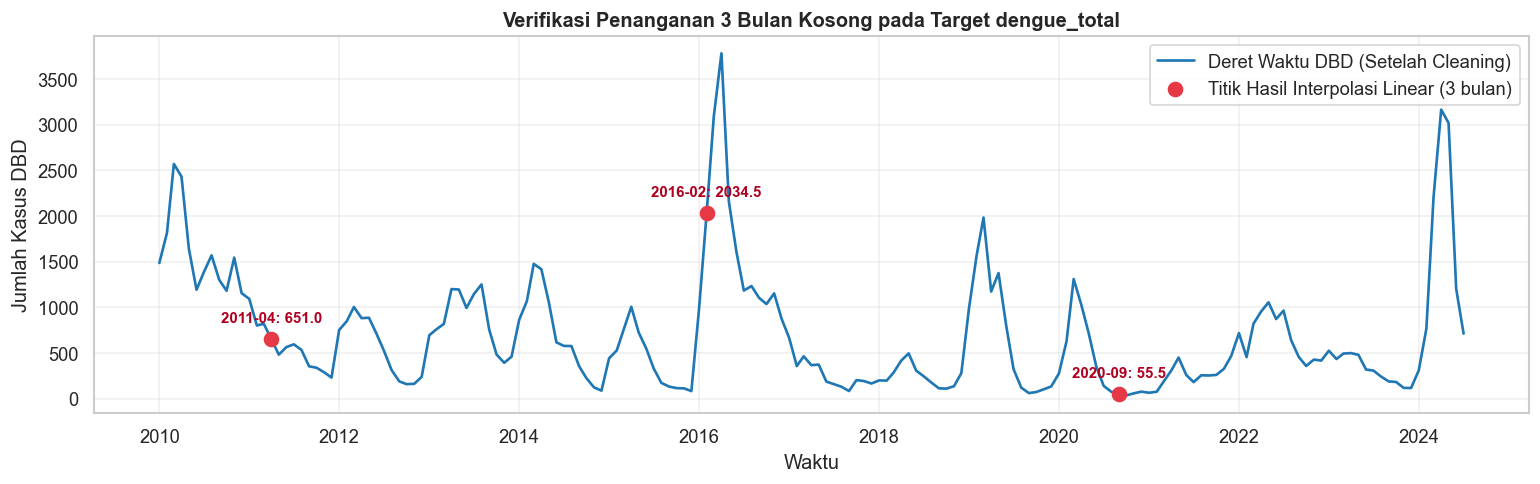

In [2]:
df_clean = df_raw.copy()

# 1. Cek dan hapus duplikat bila ada
n_dup = int(df_clean.duplicated(subset=["ym"]).sum())
df_clean = df_clean.drop_duplicates(subset=["ym"]).sort_values("date").reset_index(drop=True)

# 2. Pastikan seluruh fitur numerik bertipe float dan bebas sentinel BMKG
weather_cols = ["Tn", "Tx", "Tavg", "RH_avg", "RR_total", "RR_mean", "rain_days", "ss", "ff_x", "ff_avg"]
for col in weather_cols + ["dengue_total"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

print("Duplikat ym ditemukan:", n_dup)
print("Missing values fitur cuaca:", int(df_clean[weather_cols].isna().sum().sum()))
print("Missing values target sebelum cleaning:", int(df_clean["dengue_total"].isna().sum()))

# Catat posisi NaN sebelum imputasi
nan_mask = df_clean["dengue_total"].isna()
nan_before = df_clean.loc[nan_mask, ["ym", "dengue_total"]].copy()

# Batas partisi kronologis awal mengacu pada 173 baris setelah lag-2:
# 2 baris awal (idx 0-1) + Train (121 baris -> idx 2..122), Val (26 baris -> idx 123..148), Test (26 baris -> idx 149..174)
lag_max = 2
n_effective = len(df_clean) - lag_max
train_boundary = lag_max + int(n_effective * 0.70)  # idx 123 (exclusive untuk train: 0..122)
val_boundary = lag_max + int(n_effective * 0.85)    # idx 149 (exclusive untuk val: 123..148)

print(f"Batas partisi bebas leakage -> Train: [0..{train_boundary-1}] ({df_clean.loc[train_boundary-1, 'ym']}), "
      f"Val: [{train_boundary}..{val_boundary-1}] ({df_clean.loc[train_boundary, 'ym']}..{df_clean.loc[val_boundary-1, 'ym']}), "
      f"Test: [{val_boundary}..{len(df_clean)-1}] ({df_clean.loc[val_boundary, 'ym']}..{df_clean.loc[len(df_clean)-1, 'ym']})")

# Interpolasi linear terisolasi PER PARTISI agar tidak mengambil informasi dari partisi berikutnya
part_train = df_clean.iloc[:train_boundary].copy()
part_val = df_clean.iloc[train_boundary:val_boundary].copy()
part_test = df_clean.iloc[val_boundary:].copy()

part_train["dengue_total"] = part_train["dengue_total"].interpolate(method="linear")
part_val["dengue_total"] = part_val["dengue_total"].interpolate(method="linear")
part_test["dengue_total"] = part_test["dengue_total"].interpolate(method="linear")

df_clean = pd.concat([part_train, part_val, part_test], ignore_index=True)

nan_after = df_clean.loc[nan_mask, ["ym", "dengue_total"]].rename(columns={"dengue_total": "dengue_interpolated"})
imputation_report = nan_before.merge(nan_after, on="ym")
print("\nHasil interpolasi linear per partisi:")
display(imputation_report)
print("Total missing values setelah cleaning:", int(df_clean.isna().sum().sum()))

# Visualisasi hasil interpolasi 3 titik kosong
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(df_clean["date"], df_clean["dengue_total"], color="#1f77b4", linewidth=1.6, label="Deret Waktu DBD (Setelah Cleaning)")
ax.scatter(
    df_clean.loc[nan_mask, "date"],
    df_clean.loc[nan_mask, "dengue_total"],
    color="#e63946",
    s=70,
    zorder=5,
    label="Titik Hasil Interpolasi Linear (3 bulan)",
)
for _, r in df_clean.loc[nan_mask].iterrows():
    ax.annotate(f"{r['ym']}: {r['dengue_total']:.1f}", (r["date"], r["dengue_total"]),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9, fontweight="bold", color="#b00020")
ax.set_title("Verifikasi Penanganan 3 Bulan Kosong pada Target dengue_total", fontweight="bold")
ax.set_xlabel("Waktu")
ax.set_ylabel("Jumlah Kasus DBD")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_05_cleaning_interpolation.png", dpi=150)
plt.show()

**Analisis Bab 5.1:**
- Ketiga bulan kosong terisolasi (`2011-04`, `2016-02` berada di dalam rentang Training; `2020-09` berada di dalam rentang Validation; dan Test memiliki `0` missing value) berhasil diisi melalui **interpolasi linear terisolasi per partisi**, sehingga deret kalender tetap kontinu untuk pembuatan lag & jendela LSTM tanpa terjadi kebocoran antar split.
- Seluruh outlier puncak kejadian DBD (mis. 2016 & 2024) serta hujan ekstrem **tetap dipertahankan** karena merupakan fenomena epidemiologis nyata yang menjadi fokus prediksi model.

## 5.2 Feature Engineering (Time Lag 1-2 Bulan & Siklikal Musiman)

In [3]:
df_feat = df_clean.copy()

# 1. Fitur lag target (t-1 dan t-2)
df_feat["dengue_lag1"] = df_feat["dengue_total"].shift(1)
df_feat["dengue_lag2"] = df_feat["dengue_total"].shift(2)

# 2. Fitur lag seluruh variabel meteorologi (t-1 dan t-2, TANPA lag 0 untuk mencegah leakage)
for col in weather_cols:
    df_feat[f"{col}_lag1"] = df_feat[col].shift(1)
    df_feat[f"{col}_lag2"] = df_feat[col].shift(2)

# 3. Rolling mean 2 bulan terakhir yang digeser shift(1) (hanya memakai t-1 dan t-2)
rolling_targets = ["dengue_total", "RH_avg", "RR_total", "rain_days", "Tavg"]
for col in rolling_targets:
    prefix = "dengue" if col == "dengue_total" else col
    df_feat[f"{prefix}_roll2_mean"] = df_feat[col].shift(1).rolling(window=2).mean()

# 4. Encoding siklikal bulan (kalender deterministik bulan t)
df_feat["month_sin"] = np.sin(2 * np.pi * df_feat["month"] / 12.0)
df_feat["month_cos"] = np.cos(2 * np.pi * df_feat["month"] / 12.0)

# Hapus 2 baris awal (2010-01 dan 2010-02) yang belum punya riwayat 2 bulan
df_model = df_feat.iloc[lag_max:].reset_index(drop=True)

# Susun daftar tepat 29 fitur prediktor (bebas cuaca lag 0)
feature_cols = (
    ["dengue_lag1", "dengue_lag2"]
    + [f"{c}_lag1" for c in weather_cols]
    + [f"{c}_lag2" for c in weather_cols]
    + ["dengue_roll2_mean", "RH_avg_roll2_mean", "RR_total_roll2_mean", "rain_days_roll2_mean", "Tavg_roll2_mean"]
    + ["month_sin", "month_cos"]
)

print(f"Total baris efektif setelah lag 1-2 bulan: {len(df_model)} baris ({df_model['ym'].iloc[0]} s.d. {df_model['ym'].iloc[-1]})")
print(f"Total fitur prediktor terbentuk: {len(feature_cols)} fitur")
print("Daftar fitur:", feature_cols)
print("Missing values pada matriks fitur+target:", int(df_model[feature_cols + ['dengue_total']].isna().sum().sum()))
display(df_model[["ym", "dengue_total", "dengue_lag1", "dengue_lag2", "rain_days_lag2", "RH_avg_lag2", "month_sin", "month_cos"]].head())

Total baris efektif setelah lag 1-2 bulan: 173 baris (2010-03 s.d. 2024-07)
Total fitur prediktor terbentuk: 29 fitur
Daftar fitur: ['dengue_lag1', 'dengue_lag2', 'Tn_lag1', 'Tx_lag1', 'Tavg_lag1', 'RH_avg_lag1', 'RR_total_lag1', 'RR_mean_lag1', 'rain_days_lag1', 'ss_lag1', 'ff_x_lag1', 'ff_avg_lag1', 'Tn_lag2', 'Tx_lag2', 'Tavg_lag2', 'RH_avg_lag2', 'RR_total_lag2', 'RR_mean_lag2', 'rain_days_lag2', 'ss_lag2', 'ff_x_lag2', 'ff_avg_lag2', 'dengue_roll2_mean', 'RH_avg_roll2_mean', 'RR_total_roll2_mean', 'rain_days_roll2_mean', 'Tavg_roll2_mean', 'month_sin', 'month_cos']
Missing values pada matriks fitur+target: 0


,ym,dengue_total,dengue_lag1,dengue_lag2,rain_days_lag2,RH_avg_lag2,month_sin,month_cos
0,2010-03,2570.0,1815.0,1486.0,22.0,80.7903,1.000000e+00,6.123234e-17
1,2010-04,2431.0,2570.0,1815.0,18.0,80.6429,8.660254e-01,-5.000000e-01
2,2010-05,1640.0,2431.0,2570.0,12.0,78.0323,5.000000e-01,-8.660254e-01
3,2010-06,1193.0,1640.0,2431.0,6.0,73.4000,1.224647e-16,-1.000000e+00
4,2010-07,1387.0,1193.0,1640.0,13.0,76.3871,-5.000000e-01,-8.660254e-01


**Analisis Bab 5.2:**
- Dihasilkan **29 fitur prediktor** tanpa menyertakan observasi cuaca pada bulan berjalan $t$ (`lag 0`), karena pada skenario prediksi nyata awal bulan $t$, akumulasi cuaca bulanan ke-$t$ belum selesai diamati.
- Pengurangan 2 baris pertama (`2010-01` & `2010-02`) yang belum memiliki histori lengkap menghasilkan **173 sampel efektif** (`2010-03` s.d. `2024-07`) dengan **0 missing value**.

## 5.3 Data Transformation (Encoding Siklikal & Strategi Standardisasi)

In [4]:
# Verifikasi rentang fitur siklikal bulan & perbandingan skala fitur sebelum standardisasi
print("Rentang fitur siklikal:")
display(df_model[["month", "month_sin", "month_cos"]].drop_duplicates().sort_values("month").round(3))

scale_summary = df_model[feature_cols].agg(["min", "mean", "std", "max"]).T.round(2)
print("\nPerbandingan skala antar fitur (sebelum StandardScaler):")
display(scale_summary.loc[["dengue_lag1", "RR_total_lag2", "RH_avg_lag2", "Tavg_lag2", "ff_avg_lag1", "month_sin"]])

Rentang fitur siklikal:


,month,month_sin,month_cos
10,1,0.500,0.866
11,2,0.866,0.500
0,3,1.000,0.000
1,4,0.866,-0.500
2,5,0.500,-0.866
3,6,0.000,-1.000
4,7,-0.500,-0.866
5,8,-0.866,-0.500
6,9,-1.000,-0.000
7,10,-0.866,0.500



Perbandingan skala antar fitur (sebelum StandardScaler):


,min,mean,std,max
dengue_lag1,36.00,696.99,653.37,3781.00
RR_total_lag2,0.00,209.71,187.68,1060.07
RH_avg_lag2,67.45,76.28,3.99,85.55
Tavg_lag2,26.74,28.60,0.64,30.47
ff_avg_lag1,1.10,1.96,0.50,3.97
month_sin,-1.00,0.01,0.71,1.00


**Analisis Bab 5.3:**
- Variabel `month` (1-12) telah ditransformasikan menjadi pasangan **encoding siklikal (`month_sin`, `month_cos`)** agar kedekatan transisi Desember (12) ke Januari (1) terjaga di ruang fitur tanpa menambah 12 kolom dummy (*one-hot*) yang boros dimensi pada 173 sampel.
- Terlihat perbedaan rentang nilai yang sangat lebar (mis. `dengue_lag1` hingga ribuan kasus dan `RR_total_lag2` ratusan mm dibanding `ff_avg_lag1` maupun `month_sin` di kisaran `[-1, 1]`). Oleh karena itu diperlukan **`StandardScaler`**, yang proses `.fit()`-nya **wajib dilakukan setelah Bab 5.4** khusus pada partisi Training untuk mencegah *data leakage*.

## 5.4 Data Splitting (Kronologis 70:15:15) & Fitting Scaler Bebas Leakage

,Partisi,Jumlah Sampel,Proporsi (%),Rentang Bulan,Mean Target,Max Target
0,Training (70%),121,69.9,2010-03 s.d. 2020-03,747.30,3781.0
1,Validation (15%),26,15.0,2020-04 s.d. 2022-05,370.48,1055.0
2,Test (15%),26,15.0,2022-06 s.d. 2024-07,746.96,3164.0



Verifikasi Mean & Std setelah StandardScaler:
- X_train_scaled -> mean max abs: 0.000000, std min/max: 1.0000/1.0000
- X_val_scaled   -> mean rata-rata: 0.092 (tidak dipaksa 0)
- X_test_scaled  -> mean rata-rata: 0.144 (tidak dipaksa 0)


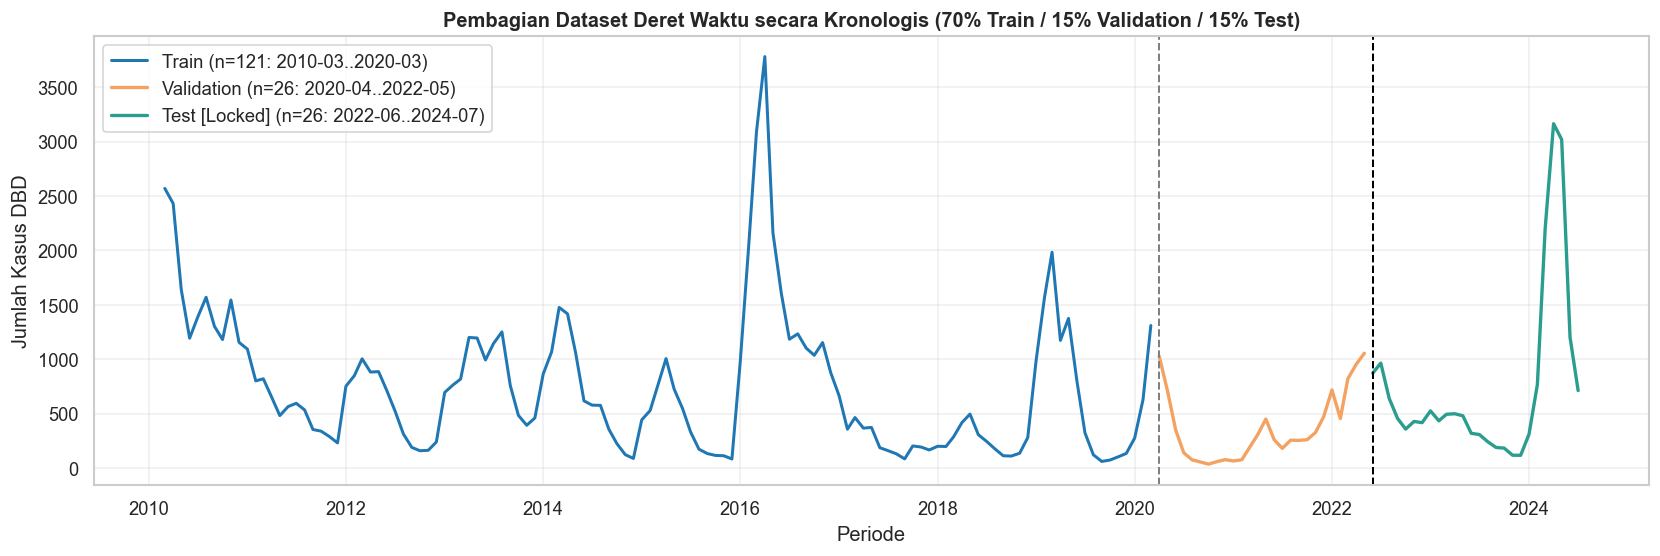


Artefak siap pakai berhasil disimpan ke: data/processed


In [5]:
n_total = len(df_model)
train_end = int(n_total * 0.70)  # 121 sampel
val_end = int(n_total * 0.85)    # 147 -> val = 26, test = 26

train_df = df_model.iloc[:train_end].copy()
val_df = df_model.iloc[train_end:val_end].copy()
test_df = df_model.iloc[val_end:].copy()

X_train = train_df[feature_cols].copy()
y_train = train_df["dengue_total"].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df["dengue_total"].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df["dengue_total"].copy()

# Fit StandardScaler HANYA pada X_train
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=feature_cols, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

split_summary = pd.DataFrame([
    {
        "Partisi": "Training (70%)",
        "Jumlah Sampel": len(train_df),
        "Proporsi (%)": round(len(train_df) / n_total * 100, 1),
        "Rentang Bulan": f"{train_df['ym'].iloc[0]} s.d. {train_df['ym'].iloc[-1]}",
        "Mean Target": round(y_train.mean(), 2),
        "Max Target": round(y_train.max(), 2),
    },
    {
        "Partisi": "Validation (15%)",
        "Jumlah Sampel": len(val_df),
        "Proporsi (%)": round(len(val_df) / n_total * 100, 1),
        "Rentang Bulan": f"{val_df['ym'].iloc[0]} s.d. {val_df['ym'].iloc[-1]}",
        "Mean Target": round(y_val.mean(), 2),
        "Max Target": round(y_val.max(), 2),
    },
    {
        "Partisi": "Test (15%)",
        "Jumlah Sampel": len(test_df),
        "Proporsi (%)": round(len(test_df) / n_total * 100, 1),
        "Rentang Bulan": f"{test_df['ym'].iloc[0]} s.d. {test_df['ym'].iloc[-1]}",
        "Mean Target": round(y_test.mean(), 2),
        "Max Target": round(y_test.max(), 2),
    },
])
display(split_summary)

# Verifikasi ketat anti-leakage
assert train_df["date"].max() < val_df["date"].min() < test_df["date"].min(), "Urutan waktu split bertumpuk!"
assert int(X_train_scaled.isna().sum().sum()) == 0
assert int(X_val_scaled.isna().sum().sum()) == 0
assert int(X_test_scaled.isna().sum().sum()) == 0

print("\nVerifikasi Mean & Std setelah StandardScaler:")
print(f"- X_train_scaled -> mean max abs: {X_train_scaled.mean().abs().max():.6f}, std min/max: {X_train_scaled.std(ddof=0).min():.4f}/{X_train_scaled.std(ddof=0).max():.4f}")
print(f"- X_val_scaled   -> mean rata-rata: {X_val_scaled.mean().mean():.3f} (tidak dipaksa 0)")
print(f"- X_test_scaled  -> mean rata-rata: {X_test_scaled.mean().mean():.3f} (tidak dipaksa 0)")

# Visualisasi pembagian kronologis 70:15:15
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(train_df["date"], y_train, color="#1f77b4", linewidth=1.8, label=f"Train (n={len(train_df)}: {train_df['ym'].iloc[0]}..{train_df['ym'].iloc[-1]})")
ax.plot(val_df["date"], y_val, color="#f4a261", linewidth=2.0, label=f"Validation (n={len(val_df)}: {val_df['ym'].iloc[0]}..{val_df['ym'].iloc[-1]})")
ax.plot(test_df["date"], y_test, color="#2a9d8f", linewidth=2.0, label=f"Test [Locked] (n={len(test_df)}: {test_df['ym'].iloc[0]}..{test_df['ym'].iloc[-1]})")
ax.axvline(val_df["date"].iloc[0], color="gray", linestyle="--", linewidth=1.2)
ax.axvline(test_df["date"].iloc[0], color="black", linestyle="--", linewidth=1.2)
ax.set_title("Pembagian Dataset Deret Waktu secara Kronologis (70% Train / 15% Validation / 15% Test)", fontsize=12, fontweight="bold")
ax.set_xlabel("Periode")
ax.set_ylabel("Jumlah Kasus DBD")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_06_chronological_split.png", dpi=150)
plt.show()

# Simpan dataset hasil persiapan ke data/processed/ (di-ignore Git, siap dipakai Minggu 3+)
df_clean.to_csv(PROCESSED_DIR / "clean_monthly_base.csv", index=False)
train_df[["ym", "date"] + feature_cols + ["dengue_total"]].to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df[["ym", "date"] + feature_cols + ["dengue_total"]].to_csv(PROCESSED_DIR / "val.csv", index=False)
test_df[["ym", "date"] + feature_cols + ["dengue_total"]].to_csv(PROCESSED_DIR / "test.csv", index=False)

pd.concat([train_df[["ym", "date"]].reset_index(drop=True), X_train_scaled.reset_index(drop=True), y_train.reset_index(drop=True)], axis=1).to_csv(PROCESSED_DIR / "train_scaled.csv", index=False)
pd.concat([val_df[["ym", "date"]].reset_index(drop=True), X_val_scaled.reset_index(drop=True), y_val.reset_index(drop=True)], axis=1).to_csv(PROCESSED_DIR / "val_scaled.csv", index=False)
pd.concat([test_df[["ym", "date"]].reset_index(drop=True), X_test_scaled.reset_index(drop=True), y_test.reset_index(drop=True)], axis=1).to_csv(PROCESSED_DIR / "test_scaled.csv", index=False)

with open(PROCESSED_DIR / "scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

meta = {
    "random_state": RANDOM_STATE,
    "n_raw_rows": int(len(df_raw)),
    "n_effective_rows": int(n_total),
    "split_sizes": {"train": int(len(train_df)), "val": int(len(val_df)), "test": int(len(test_df))},
    "feature_cols": feature_cols,
    "target_col": "dengue_total",
}
(PROCESSED_DIR / "feature_metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("\nArtefak siap pakai berhasil disimpan ke:", PROCESSED_DIR.relative_to(PROJECT_ROOT).as_posix())

## Ringkasan Data Preparation (Sampai Bab 5.4 sesuai Arahan LKM 11)

> *Catatan ruang lingkup: Sesuai arahan penugasan sampai nomor 6 (Bab 5.4), tahap 5.5 (Data Balancing) tidak dijalankan pada tahap ini dan secara metodologis tidak diperlukan karena tugas berupa regresi deret waktu kontinu.*

### Data Analysis Key Findings
- **Bab 5.1 (Cleaning):** `0` baris duplikat; `0` missing value cuaca; `3` bulan target kosong (`2011-04`, `2016-02`, `2020-09`) diimputasi dengan interpolasi linear terisolasi di dalam masing-masing rentang partisi, sedangkan outlier KLB tetap dipertahankan.
- **Bab 5.2 - 5.3 (Feature Engineering & Transformasi):** Dibentuk **29 fitur prediktor** berbasis masa lalu (`lag 1` & `lag 2` untuk target dan 10 parameter cuaca, `rolling mean 2 bulan` dengan `shift 1`, serta `month_sin` & `month_cos`) **tanpa menyertakan fitur cuaca `lag 0`**, menghasilkan **173 sampel efektif** (`2010-03` s.d. `2024-07`).
- **Bab 5.4 (Splitting & Anti-Leakage Scaling):** Data dibagi secara kronologis (`70:15:15`) menjadi **121 sampel Training (`2010-03..2020-03`)**, **26 sampel Validation (`2020-04..2022-05`)**, dan **26 sampel Test (`2022-06..2024-07`)**. `StandardScaler` di-*fit* **hanya pada `X_train`** dan seluruh artefak siap pakai telah disimpan di `data/processed/`.

### Insights or Next Steps
- **Test set (`2022-06` s.d. `2024-07`, `n=26`)** dikunci dan tidak boleh disentuh sampai evaluasi akhir (Minggu 6 / Tahap `[P]`).
- Langkah selanjutnya di **Minggu 3 (LKM / Tahap `[M]`)** adalah membangun dan mengevaluasi Model Baseline (**Naive Forecaster** $\hat{y}_t = y_{t-1}$) serta **XGBoost Regressor** pada data Validation (`train.csv` / `val.csv`).